In [1]:
# Librries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# dataset
df = pd.read_csv("credit_card_fraud_dataset.csv")  


In [2]:
# Check few rows
df.head()


,TransactionID,CustomerID,Amount,MerchantCategory,Hour,Region,DeviceType,PreviousFraud,IsInternational,IsFraud
0,TXN000000,CUST00103,22.50,Electronics,8,North,Desktop,0,1,0
1,TXN000001,CUST00436,30.82,Restaurant,23,West,Mobile,1,0,1
2,TXN000002,CUST00861,18.60,Grocery,18,East,Desktop,0,0,0
3,TXN000003,CUST00271,10.05,Travel,16,East,Mobile,0,0,0
4,TXN000004,CUST00107,54.32,Restaurant,9,West,Mobile,0,0,0


In [3]:
# info about columns and datatypes
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   TransactionID     10000 non-null  object 
 1   CustomerID        10000 non-null  object 
 2   Amount            10000 non-null  float64
 3   MerchantCategory  10000 non-null  object 
 4   Hour              10000 non-null  int64  
 5   Region            10000 non-null  object 
 6   DeviceType        10000 non-null  object 
 7   PreviousFraud     10000 non-null  int64  
 8   IsInternational   10000 non-null  int64  
 9   IsFraud           10000 non-null  int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 781.4+ KB


In [4]:
# Checking  missing values
df.isnull().sum()


TransactionID       0
CustomerID          0
Amount              0
MerchantCategory    0
Hour                0
Region              0
DeviceType          0
PreviousFraud       0
IsInternational     0
IsFraud             0
dtype: int64

In [5]:
# Checking for  unique values in categorical features
for col in df.select_dtypes(include='object').columns:
    print(f"{col}: {df[col].nunique()} unique values")


TransactionID: 10000 unique values
CustomerID: 1000 unique values
MerchantCategory: 7 unique values
Region: 5 unique values
DeviceType: 3 unique values


In [6]:
# Drop ID columns that are not needed
df.drop(columns=['TransactionID', 'CustomerID'], inplace=True)

# Encode categorical variables using one-hot encoding
df = pd.get_dummies(df, drop_first=True)

# checking the changes in the dataset
df.head()


,Amount,Hour,PreviousFraud,IsInternational,IsFraud,MerchantCategory_Electronics,MerchantCategory_Fuel,MerchantCategory_Grocery,MerchantCategory_Online Services,MerchantCategory_Restaurant,MerchantCategory_Travel,Region_East,Region_North,Region_South,Region_West,DeviceType_Mobile,DeviceType_Tablet
0,22.50,8,0,1,0,True,False,False,False,False,False,False,True,False,False,False,False
1,30.82,23,1,0,1,False,False,False,False,True,False,False,False,False,True,True,False
2,18.60,18,0,0,0,False,False,True,False,False,False,True,False,False,False,False,False
3,10.05,16,0,0,0,False,False,False,False,False,True,True,False,False,False,True,False
4,54.32,9,0,0,0,False,False,False,False,True,False,False,False,False,True,True,False


# Distribution of Fraud vs Non-Fraud:

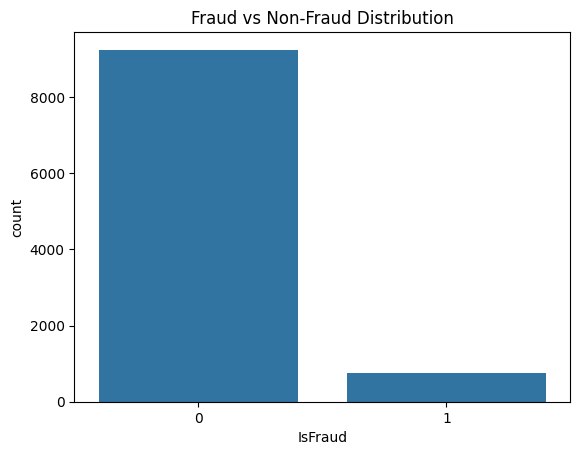

Fraudulent Transactions: 7.54%


In [7]:
sns.countplot(x='IsFraud', data=df)
plt.title("Fraud vs Non-Fraud Distribution")
plt.show()

# Print percentage
fraud_percent = df['IsFraud'].mean() * 100
print(f"Fraudulent Transactions: {fraud_percent:.2f}%")


# Transaction Amount by Fraud Status:

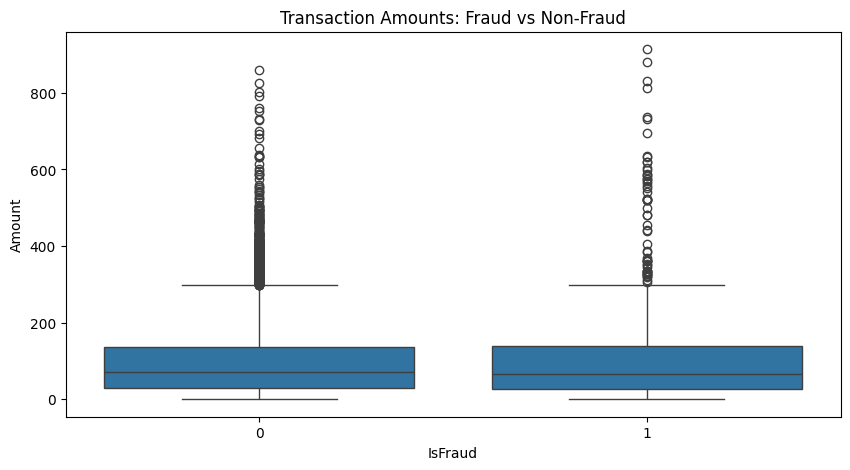

In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='IsFraud', y='Amount', data=df)
plt.title("Transaction Amounts: Fraud vs Non-Fraud")
plt.show()


# FRAUD BY HOUR

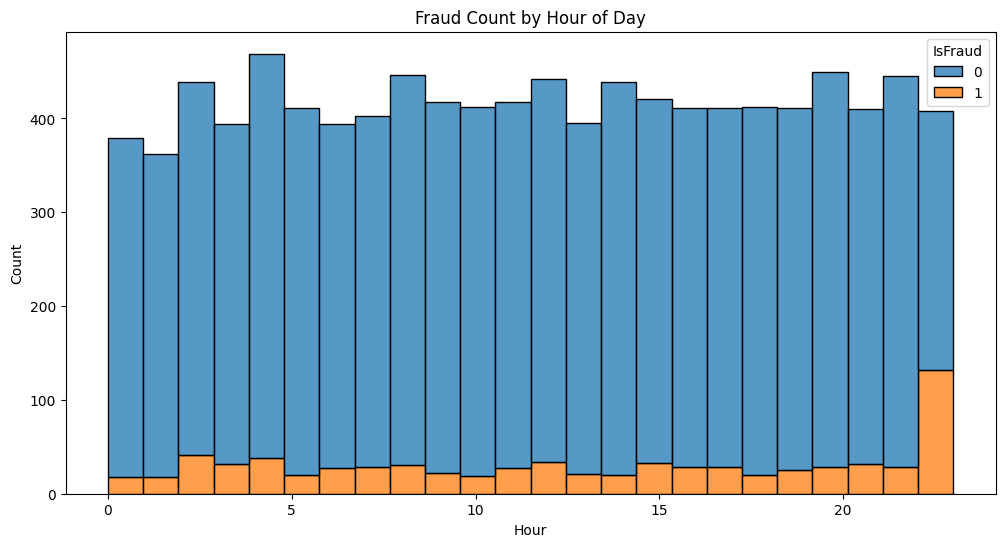

In [9]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='Hour', hue='IsFraud', bins=24, multiple='stack')
plt.title("Fraud Count by Hour of Day")
plt.xlabel("Hour")
plt.show()


# correlation of heatmap

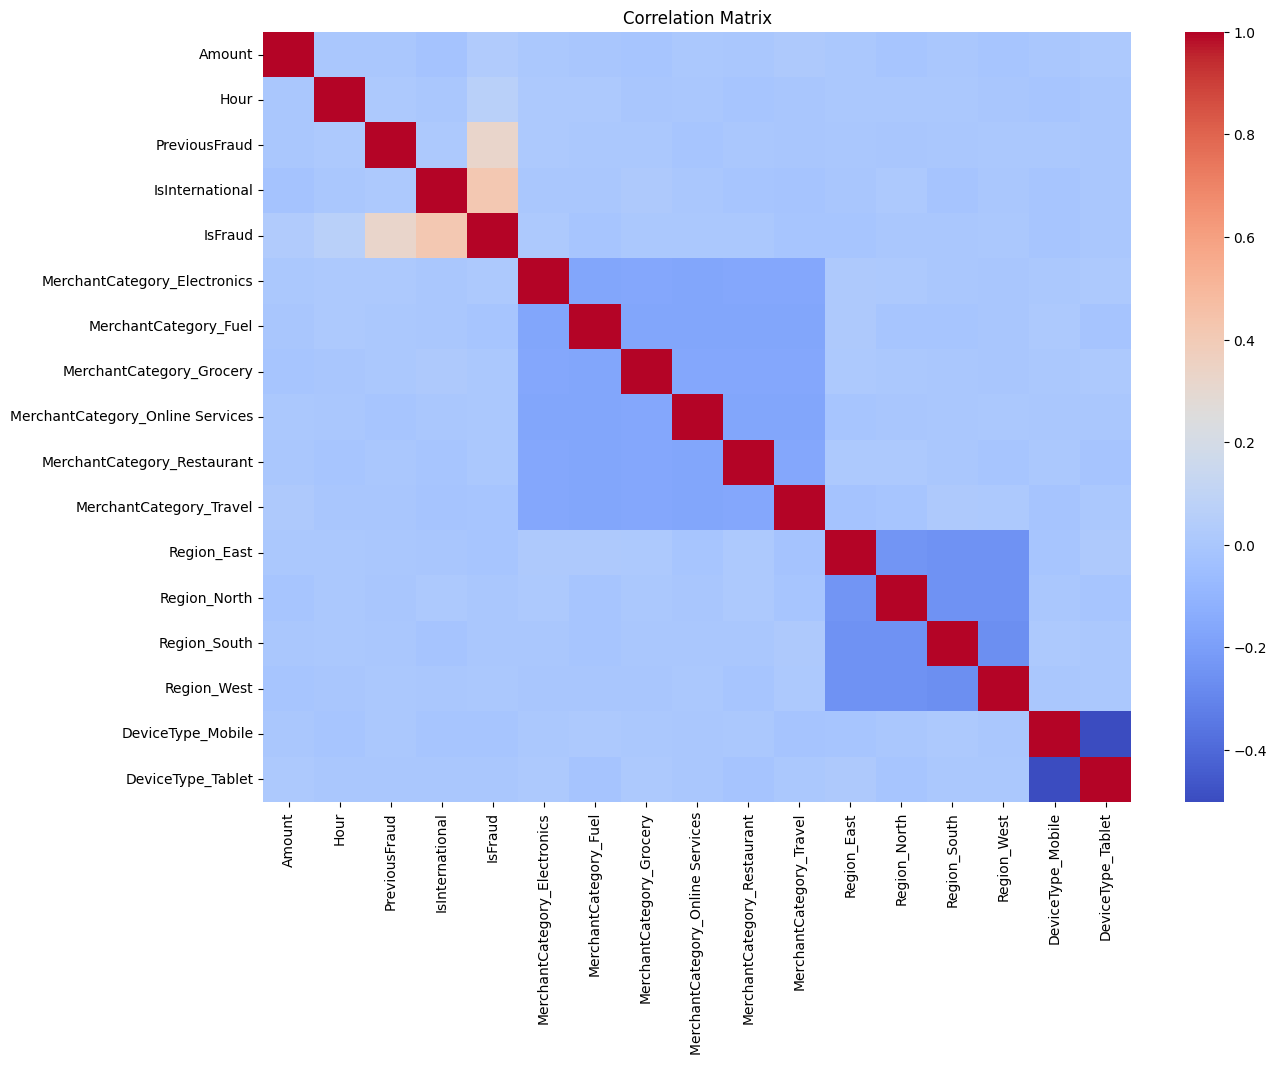

In [13]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


# Transactions with unusually high amounts could be more likely to be fraudulent.

In [14]:
high_amount_threshold = 1000
df['HighAmountFlag'] = (df['Amount'] > high_amount_threshold).astype(int)

df[['Amount', 'HighAmountFlag']].head()


,Amount,HighAmountFlag
0,22.50,0
1,30.82,0
2,18.60,0
3,10.05,0
4,54.32,0


# Times of the day might have a higher likelihood of fraud.

In [15]:

peak_hours = [0, 1, 2, 3, 4, 5, 22, 23]  # morning/late night hours
df['PeakHourFlag'] = df['Hour'].isin(peak_hours).astype(int)

df[['Hour', 'PeakHourFlag']].head()


,Hour,PeakHourFlag
0,8,0
1,23,1
2,18,0
3,16,0
4,9,0


# Train-Test Split

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['IsFraud'])
y = df['IsFraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data shape: {X_train.shape}")
print(f"Test data shape: {X_test.shape}")


Training data shape: (8000, 18)
Test data shape: (2000, 18)


# Model Building

Accuracy: 0.9190
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      1850
           1       0.41      0.19      0.26       150

    accuracy                           0.92      2000
   macro avg       0.67      0.58      0.61      2000
weighted avg       0.90      0.92      0.90      2000



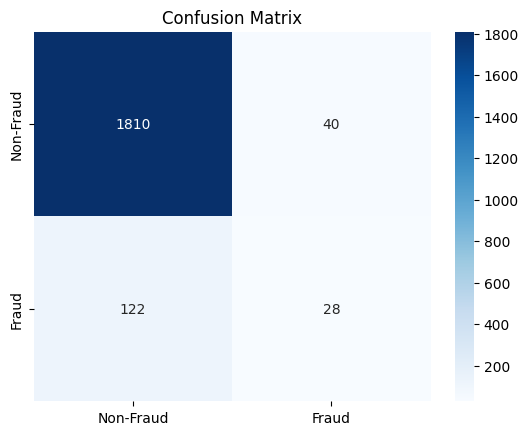

In [19]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model on the training data
rf_model.fit(X_train, y_train)

# Make predictions using the test data
y_pred = rf_model.predict(X_test)

# Import tools to check how well the model is doing
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate and print the accuracy (how many predictions were correct)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Print a report that shows precision, recall, and F1 score for each class
print(classification_report(y_test, y_pred))

# Create and show a heatmap (visual chart) of the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Non-Fraud", "Fraud"], 
            yticklabels=["Non-Fraud", "Fraud"])
plt.title("Confusion Matrix")
plt.show()


# Model Evaluation

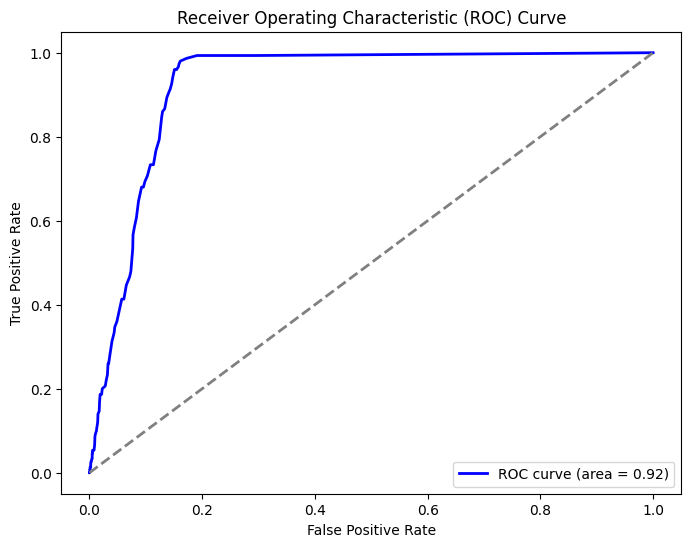

In [20]:
# ROC Curve and AUC Score
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, rf_model.predict_proba(X_test)[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()


In [21]:
import joblib

# Save model
joblib.dump(rf_model, 'fraud_model.pkl')


loaded_model = joblib.load('fraud_model.pkl')
y_pred = loaded_model.predict(X_test)
